# Stage 4: Neural network comparison (MLP)

**Question.** Would a neural network do better than the logit and LightGBM? The data are tabular (one row per shot, 15
features), so recurrent or convolutional networks do not apply; the natural neural model is a multilayer perceptron
(MLP). Published benchmarks on tabular data (Grinsztajn et al. 2022) find tree ensembles at least as good as neural
networks on data of this size, and we check it on our problem.

**Protocol**, identical to the LightGBM tuning in `05_lightgbm.ipynb`: walk-forward, 2-season window; for test season S
the hyperparameters and the number of epochs are chosen on S-1 (train on S-2), then the network is refitted on both
seasons and predicts S. The test season never influences a choice. The MLP gets the same features as the main model
(shot + context). Training runs on the GPU if available.

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from xpts.metrics import calibration_table, evaluate, paired_bootstrap
from xpts.mlp import DEFAULT_PARAMS, MLP_FEATURES, MLPModel, tune_mlp
from xpts.validation import HOLDOUT_SEASON, walk_forward

FIG_DIR = Path("../reports/figures")
KEY = ["GAME_ID", "GAME_EVENT_ID"]

df = pd.read_parquet("../data/processed/shots_features.parquet")
df = df[df["SEASON"] != HOLDOUT_SEASON].reset_index(drop=True)  # hold-out season, never used here
df = df.merge(pd.read_parquet("../data/processed/shots_context.parquet"), on=KEY, how="left", validate="1:1")
y = df["SHOT_MADE_FLAG"]
print(f"shots: {len(df):,}, device: {'cuda: ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}")

shots: 2,305,805, device: cuda: NVIDIA GeForce RTX 5060 Ti


## 1. Model

`MLPModel` (in `src/xpts/mlp.py`):
- **numeric features** are standardised with the training mean and standard deviation (a network, unlike trees, is
  sensitive to the scale); missing context values become 0 and get an indicator column;
- **categorical features** (`action_group`, `prev_event`) go through embeddings (a learned vector per category);
- 2-3 hidden layers with ReLU and dropout, one output (logit), binary cross-entropy loss = log loss;
- AdamW optimiser, batch 2048; after every epoch the validation log loss is recorded and the best epoch is kept.

First a single fit to see the learning curve: train 2021-22, validate 2022-23.

['dist_ft', 'angle_deg', 'LOC_X', 'LOC_Y', 'is_three', 'is_corner3', 'is_heave', 'is_overtime', 'PERIOD', 'secs_left_period', 'action_group', 'is_home', 'prev_event', 'secs_since_prev', 'score_margin']
{'hidden': 128, 'layers': 2, 'dropout': 0.0, 'lr': 0.001, 'weight_decay': 1e-05, 'batch_size': 2048, 'epochs': 30}


64 x 2, no dropout: best epoch 15, validation log loss 0.6403


64 x 2, dropout 0.2: best epoch 35, validation log loss 0.6396


256 x 3, dropout 0.2: best epoch 16, validation log loss 0.6400


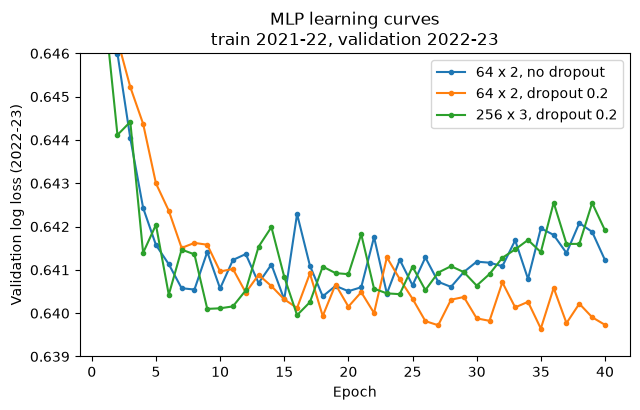

In [2]:
print(MLP_FEATURES)
print(DEFAULT_PARAMS)
a, b = df["SEASON"] == "2021-22", df["SEASON"] == "2022-23"
curves = {}
for label, params in {"64 x 2, no dropout": dict(hidden=64, layers=2, dropout=0.0),
                      "64 x 2, dropout 0.2": dict(hidden=64, layers=2, dropout=0.2),
                      "256 x 3, dropout 0.2": dict(hidden=256, layers=3, dropout=0.2)}.items():
    m = MLPModel(**params, epochs=40).fit(df[a], y[a], df[b], y[b])
    curves[label] = m.history_
    print(f"{label}: best epoch {m.best_epoch_}, validation log loss {min(m.history_):.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for label, h in curves.items():
    ax.plot(range(1, len(h) + 1), h, marker="o", ms=3, label=label)
ax.set(xlabel="Epoch", ylabel="Validation log loss (2022-23)", ylim=(0.639, 0.646),
       title="MLP learning curves\ntrain 2021-22, validation 2022-23")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_mlp_learning_curves.pdf")
plt.show()

## 2. Tuning and walk-forward evaluation

**Grid** (16 combinations): hidden width {64, 256} x layers {2, 3} x dropout {0, 0.2} x learning rate {0.001, 0.003},
up to 40 epochs. The first fold (test 2015-16) has one training season and uses the default parameters.

In [3]:
grid = [dict(hidden=h, layers=l, dropout=d, lr=lr)
        for h in (64, 256) for l in (2, 3) for d in (0.0, 0.2) for lr in (1e-3, 3e-3)]
oos = pd.read_parquet("../data/processed/oos_predictions.parquet")  # logit and LightGBM predictions (06_main_model)
chosen, rows = [], []
for season, tr, te in walk_forward(df["SEASON"], window=2):
    train_seasons = sorted(df.loc[tr, "SEASON"].unique())
    params = {}
    if len(train_seasons) == 2:
        inner_tr = (df["SEASON"] == train_seasons[0]).to_numpy()
        inner_val = (df["SEASON"] == train_seasons[1]).to_numpy()
        best = tune_mlp(df[inner_tr], y[inner_tr], df[inner_val], y[inner_val], grid).iloc[0]
        params = dict(hidden=int(best["hidden"]), layers=int(best["layers"]), dropout=float(best["dropout"]),
                      lr=float(best["lr"]), epochs=int(best["epochs"]))
        chosen.append({"season": season, **params, "val_log_loss": best["val_log_loss"]})
    p = MLPModel(**params).fit(df[tr], y[tr]).predict_proba(df[te])[:, 1]
    oos.loc[df.index[te], "mlp_w2_ctx"] = p
    rows.append({"model": "mlp_w2_ctx", "season": season, **evaluate(y[te], p)})

oos.to_parquet("../data/processed/oos_predictions.parquet")
display(pd.DataFrame(chosen).set_index("season").round(4))

,hidden,layers,dropout,lr,epochs,val_log_loss
season,,,,,,
2016-17,64,2,0.2,0.003,17,0.6330
2017-18,64,2,0.2,0.001,38,0.6356
2018-19,64,3,0.2,0.003,29,0.6462
2019-20,64,2,0.2,0.003,32,0.6361
2020-21,64,2,0.2,0.003,31,0.6372
2021-22,64,3,0.2,0.001,33,0.6436
2022-23,64,2,0.2,0.003,38,0.6387
2023-24,64,3,0.2,0.003,30,0.6395
2024-25,64,2,0.2,0.003,31,0.6401


In [4]:
order = ["logit_w1_ctx", "gbm_w2_ctx", "mlp_w2_ctx"]
res = pd.DataFrame([{"model": m, "season": s, **evaluate(g["y"], g[m])} for m in order for s, g in oos.groupby("SEASON")])
display(res.groupby("model")[["log_loss", "brier", "auc"]].mean().loc[order].round(4))
display(res.pivot(index="season", columns="model", values="log_loss")[order].round(4))

after = oos["SEASON"] >= "2018-19"
ci = pd.DataFrame({(f"mlp_w2_ctx - {ref}", period): paired_bootstrap(oos.loc[m, "y"], oos.loc[m, "mlp_w2_ctx"],
                                                                     oos.loc[m, ref], oos.loc[m, "GAME_ID"])
                   for ref in ["gbm_w2_ctx", "logit_w1_ctx"]
                   for period, m in [("all", oos["y"].notna()), ("2018-19+", after)]}).T
display(ci.round(5))
bias = oos.groupby("SEASON")[order].mean().rsub(oos.groupby("SEASON")["y"].mean(), axis=0)
display(bias.round(3))

,log_loss,brier,auc
model,,,
logit_w1_ctx,0.6390,0.2250,0.6583
gbm_w2_ctx,0.6390,0.2251,0.6580
mlp_w2_ctx,0.6399,0.2254,0.6575


model,logit_w1_ctx,gbm_w2_ctx,mlp_w2_ctx
season,,,
2015-16,0.6333,0.6323,0.6366
2016-17,0.6355,0.6340,0.6358
2017-18,0.6483,0.6539,0.6461
2018-19,0.6358,0.6359,0.6388
2019-20,0.6359,0.6357,0.6361
2020-21,0.6436,0.6433,0.6449
2021-22,0.6385,0.6379,0.6393
2022-23,0.6393,0.6385,0.6398
2023-24,0.6400,0.6391,0.6411


diff   ci_low  ci_high  share_a_better
mlp_w2_ctx - gbm_w2_ctx   all       0.00092  0.00080  0.00105             0.0
                          2018-19+  0.00157  0.00144  0.00169             0.0
mlp_w2_ctx - logit_w1_ctx all       0.00087  0.00074  0.00100             0.0
                          2018-19+  0.00105  0.00089  0.00119             0.0

,logit_w1_ctx,gbm_w2_ctx,mlp_w2_ctx
SEASON,,,
2015-16,-0.012,-0.011,-0.005
2016-17,0.001,-0.004,-0.010
2017-18,-0.007,0.006,-0.004
2018-19,-0.007,-0.009,0.003
2019-20,0.004,0.000,-0.001
2020-21,0.016,0.015,0.008
2021-22,-0.002,0.005,0.004
2022-23,0.010,0.009,0.007
2023-24,0.001,0.006,-0.006


**Observations.**
- The tuned MLP is **worse** than both other models with the same features: mean log loss 0.6399 vs 0.6390 (LightGBM) and
  0.6390 (logit). Paired bootstrap: MLP − LightGBM +0.0009 [0.0008; 0.0011], MLP − logit +0.0009 [0.0007; 0.0010]; after
  2018-19 the gap to LightGBM grows to +0.0016.
- It loses to LightGBM in 9 of 10 seasons. The exception is 2017-18 (label change), where it is the best of the three
  (0.6461): like the logit, the smooth network degrades more gracefully than the trees when the labels change.
- Tuning always chooses the **small** network (64 units, dropout 0.2); the 256-unit networks overfit after a few epochs
  (learning curves in section 1). More capacity does not help, the same conclusion as for the LightGBM tuning.
- The validation loss fluctuates by about ±0.0005 between epochs, as much as the differences between configurations, so
  the choice of the epoch is partly noise. This instability is a practical disadvantage against LightGBM, which gives the
  same result with default parameters in 10 s on a CPU.
- Conclusion: on this tabular problem (15 features, about 430 thousand training shots per fold) the neural network gives
  no gain over gradient boosting, in line with Grinsztajn et al. (2022). LightGBM stays the main model.
- Three different model families (splines + logit, trees, neural network) end within 0.001 of each other, while new
  information moves the result by 0.002 (context) to 0.009 (tracking, `08_kaggle_defence.ipynb`): the limit is the data.